# Скоринг YouTube-каналов для медиабаинга

**Задача:** Снизить риски неэффективных рекламных закупок, оценивая каналы не только по охвату, но и по вовлеченности (ER) и стабильности.

**Что сделано:**
1. Очистка данных и исключение Shorts (искажают метрики).
2. Проверка гипотез (H1: размер vs ER, H2: длительность vs ER). Обе гипотезы не подтвердились.
3. Расчет Stability Score (устойчивость просмотров).
4. Построение итогового скоринга и BCG-матрицы для распределения бюджета.

## Бизнес-контекст и постановка задачи

**Заказчик / Стейкхолдер:** Отдел медиазакупок / Performance-маркетинг

**Проблема:** При планировании рекламных кампаний на YouTube медиабайеры нередко опираются на размер аудитории (количество подписчиков). Однако большие каналы не всегда гарантируют высокую вовлеченность и конверсию, а бюджет может быть израсходован на каналы с накрученной, пассивной или "спящей" аудиторией

**Решение:** Разработать прозрачную, data-driven скоринговую модель, которая оценивает каналы не только по охвату, но и по качеству аудитории, стабильности контента и реальной вовлеченности, чтобы максимизровать эффективность затраченного бюджета

## Бизнес-цель
Создать инструмент (рейтинг), который позволит медиабаерам:
1. Минимизировать риски закупки рекламы на каналах с нестабильными показами - защитить рекламный бюджет от волатильности трафика 
2. Выявить "скрытые жемчужины" (каналы с высоким ER и лояльным ядром), которые дают наилучший CPE (Cost Per Engagement)
3. Оптимизировать распределение рекламного бюджета между разными каналами для диверсификации бюджета

## Методология и ключевые метрики
Анализ строится на базе парсинга открытых данных о каналах и их видео. Для повышения надежности модели применяются следующие подходы:
* **Фильтрация шума:** Исключение `Shorts` из расчётов, так как механика их потребления, лайков и алгоритмических рекомендаций отличается от длинных видео и сильно искажает классический Engagement Rate
* **Оценка стабильности (Stability Score):** Использование коэффициента вариации (CV) **просмотров в день** — age-нормализованной метрики охвата. Она устойчива к разнице в возрасте видео между каналами и напрямую отвечает на вопрос «что даст следующий выпуск»: байеру важнее гарантированные 100к просмотров на каждый выпуск, чем «лотерея» (от 10к до 2М). Для контроля чувствительности к выбросам дополнительно рассчитывается робастная альтернатива — CV на основе межквартильного размаха (IQR / median)
* **Строгая статистика:** Проверка гипотез о влиянии размера канала и длительности видео на ER проводится с использованием регрессионного анализа (OLS) и контролем неучтенной гетерогенности (Fixed Effects), чтобы исключить влияние конкретных "успешных" авторов

## Артефакты проекта
По итогам анализа формируется:
1. **Статистический отчет:** Подтверждение/опровержение гипотез о природе вовлеченности на YouTube
2. **Итоговый скоринг (CSV):** Рейтинг каналов с декомпозицией баллов (Охват, Вовлеченность, Стабильность, Динамика)
3. **Визуальная карта эффективности:** Квадрантный анализ для быстрого принятия решений


In [1]:
#=============================================== ЭТАП 0: ИМПОРТ БИБЛИОТЕК =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib import rcParams
import seaborn as sns
from scipy import stats
from scipy.stats import spearmanr
import statsmodels.formula.api as smf
import os
from IPython.display import display


# настройка стиля графиков
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 12

In [2]:
# ========================================== ЭТАП 1: ЗАГРУЗКА И ОБЪЕДИНЕНИЕ ДАННЫХ ============================================

df_channels = pd.read_csv('channels_data.csv')
df_videos = pd.read_csv('videos_data.csv')


df_united = pd.merge(df_channels, df_videos, on='channel_id', how='inner')
print(f'\nДатафреймы объединены.\nКоличество строк - {df_united.shape[0]}, количество столбцов - {df_united.shape[1]}.\n')


Датафреймы объединены.
Количество строк - 4217, количество столбцов - 20.



In [3]:
# Поиск и удаление дубликатов видео и удаление задублированных колонок

dupes = df_united['video_id'].duplicated().sum()

if dupes > 0:
    print(f"Удалено {dupes} дубликатов video_id")
    df_united.drop_duplicates(subset='video_id', keep='first', inplace=True)
else:
    print("\nДубликатов video_id не найдено.\n")

# Удаление задублированных колонок    
cols_to_drop = ['channel_title_x', 'scraped_date_x']
df_united.drop(columns=[c for c in cols_to_drop if c in df_united.columns], inplace=True)

# Переименовывание столбцов
rename_map = {col: col.replace('_y', '') for col in df_united.columns if col.endswith('_y')}
df_united.rename(columns=rename_map, inplace=True)


Дубликатов video_id не найдено.




Сумма длинных видео и шортс:  4217.


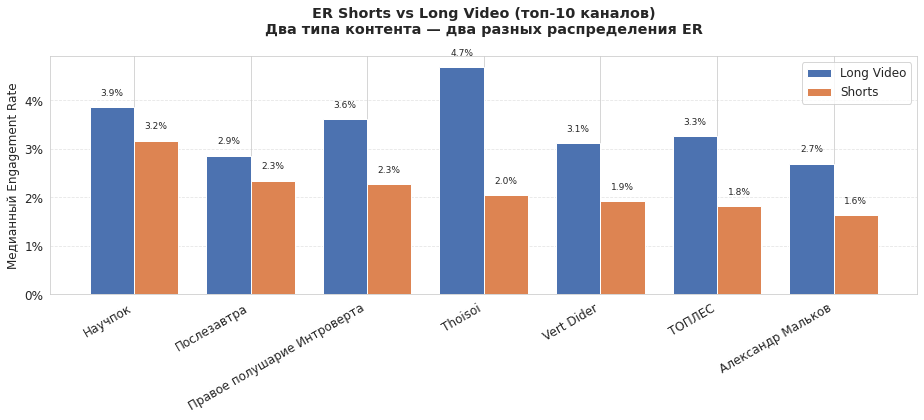

️ Медианный ER Shorts    =  1.83%
 Медианный ER Long Video = 3.32%



In [4]:
# ========================================== ЭТАП 2: ОЧИСТКА ДАННЫХ ===========================================================
print(f"\nСумма длинных видео и шортс:  {len(df_united)}.")

# Возраст видео в днях
df_united['scraped_date'] = pd.to_datetime(df_united['scraped_date'])
df_united['published_at'] = pd.to_datetime(df_united['published_at'])
df_united['video_age_days'] = (df_united['scraped_date'] - df_united['published_at']).dt.days

# Защита от деления на ноль. Видео, опубликованные в день сбора, равны 1, а не 0
df_united.loc[df_united['video_age_days'] <= 0, 'video_age_days'] = 1

#===============================================Обоснование удаления Shorts====================================================

df_united['engagement'] = np.where(
    df_united['views'] > 0,
    (df_united['likes'] + df_united['comments']) / df_united['views'], 0)

top10_ids = df_united.drop_duplicates('channel_id').nlargest(10, 'subscribers')['channel_id']
er_pivot = (
    df_united[df_united['channel_id'].isin(top10_ids)]
    .groupby(['channel_title', 'video_type'])['engagement'].median()
    .unstack().rename(columns={'Long Video': 'ER_long', 'Shorts': 'ER_shorts'})
    .dropna().sort_values('ER_shorts', ascending=False).head(10))

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(er_pivot)); w = 0.38
b1 = ax.bar(x - w/2, er_pivot['ER_long'],   w, label='Long Video', color='#4C72B0')
b2 = ax.bar(x + w/2, er_pivot['ER_shorts'], w, label='Shorts',     color='#DD8452')
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.002, f'{h:.1%}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x); ax.set_xticklabels(er_pivot.index, rotation=30, ha='right')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_ylabel('Медианный Engagement Rate')
ax.set_title('ER Shorts vs Long Video (топ-10 каналов)\nДва типа контента — два разных распределения ER\n', fontweight='bold')
ax.legend(); ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

es = df_united[df_united['video_type']=='Shorts']['engagement'].median()
el = df_united[df_united['video_type']=='Long Video']['engagement'].median()
print(f"️ Медианный ER Shorts    =  {es:.2%}\n"
      f" Медианный ER Long Video = {el:.2%}\n")


## Обоснование удаления Shorts

Гипотеза «ER Shorts значительно отличается от длинных видео» подтвердилась: медианный ER Shorts — 1.83%, Long Video — 3.32%. Вероятная причина — больше просмотров при сопоставимом числе реакций.
Если не исключить Shorts, каналы с регулярными Shorts будут необоснованно занижены в скоринге.

In [5]:
# 4. Исключение Shorts из датафрейма
df_longs = df_united[df_united['video_type'] == 'Long Video'].copy()
print(f'\nДлинных видео для анализа - {len(df_longs)}.\n')


Длинных видео для анализа - 2337.



In [6]:
# ======================================= ЭТАП 3: FEATURE ENGINEERING И АГРЕГАЦИЯ ПО КАНАЛАМ ===================================

# 3.1. Добавление новых метрик
df_longs['engagement'] = np.where(
    df_longs['views'] > 0,
    (df_longs['likes'] + df_longs['comments']) / df_longs['views'], 0)
df_longs['views_per_day'] = df_longs['views'] / df_longs['video_age_days']
df_longs['duration_min'] = df_longs['duration_sec'] / 60

# 3.2. Агрегация на уровне каналов
agg_dict = {
    'subscribers':   'first',
    'channel_title': 'first',
    'engagement':    'median',
    'views_per_day': 'median',
    'duration_min':  'median',
    'video_id':      'count'}

df_channel_stats = (
    df_longs
    .groupby('channel_id', as_index=False)
    .agg(agg_dict)
    .rename(columns={'video_id': 'video_count'}))

# 3.3. Категоризация размера канала по квантилям (на 3 равные группы)
labels = ['Small', 'Medium', 'Large']

# Добавление границ отсечек и распаковка в две переменные
df_channel_stats['channel_size'], bins = pd.qcut(
    df_channel_stats['subscribers'],
    q=3,
    labels=labels,
    retbins=True)

print("Границы отсечек по подписчикам(интервалы):", *[int(i) for i in bins])
print('\nТаблица df_channel_stats выглядит следующим образом:')
df_channel_stats.head(3)

Границы отсечек по подписчикам(интервалы): 27600 503000 1730000 7780000

Таблица df_channel_stats выглядит следующим образом:


,channel_id,subscribers,channel_title,engagement,views_per_day,duration_min,video_count,channel_size
0,UC-_iyv1-5NM5wmypELjz8Aw,1880000,Максим Кузнецов,0.034933,2196.295658,1.508333,336,Large
1,UC09VpabKaMl-CAq5piB_7oA,27600,Ученые против мифов,0.047959,324.811817,59.808333,26,Small
2,UC1bFQRZLgbShAkKGY0UMrWQ,1250000,Глеб Соломин,0.026593,9019.092644,69.041667,28,Medium


## Этап 3.5: Разведочный анализ данных (EDA)

Необходимо визуально оценить природу данных. Для YouTube-каналов характерны следующие особенности, которые будут проверяться в рамках EDA:
1. **Сильная правая асимметрия (Long Tail):** Несколько каналов-гигантов могут искажать средние значения, поэтому нужно посмотреть на распределения в логарифмическом масштабе.
2. **Связь размера и вовлеченности:** нужно визуально проверить, падает ли ER с ростом аудитории (гипотеза №1).
3. **Мультиколлинеарность:** нужно убедиться, что признаки для скоринга не дублируют друг друга, чтобы веса в итоговой модели были обоснованными.

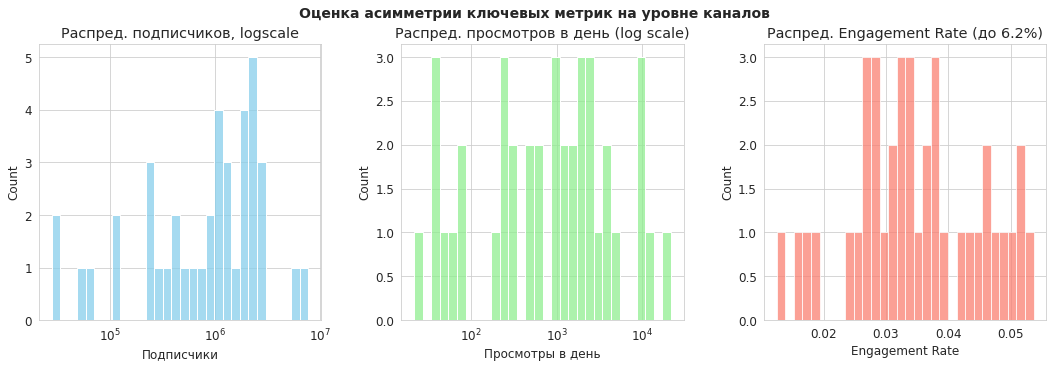

In [7]:
# ========================================== EDA 1: Оценка ключевых метрик по каналам ==========================================

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

configs = [
    ('subscribers',      True,  'skyblue',   'Подписчики',              'Распред. подписчиков, logscale'),
    ('views_per_day',    True,  'lightgreen','Просмотры в день',        'Распред. просмотров в день (log scale)'),
    ('engagement',       False, 'salmon',    'Engagement Rate',         None),]  # title задаётся ниже

for ax, (col, log_scale, color, xlabel, title) in zip(axes, configs):
    data = df_channel_stats[col]
    if col == 'engagement':
        q99 = data.quantile(0.99)
        data = data[data <= q99]
        title = f'Распред. Engagement Rate (до {q99:.1%})'
    sns.histplot(data, ax=ax, log_scale=log_scale, color=color, bins=30)
    ax.set_title(title); ax.set_xlabel(xlabel)

plt.suptitle('Оценка асимметрии ключевых метрик на уровне каналов', 
             fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout(); plt.show()

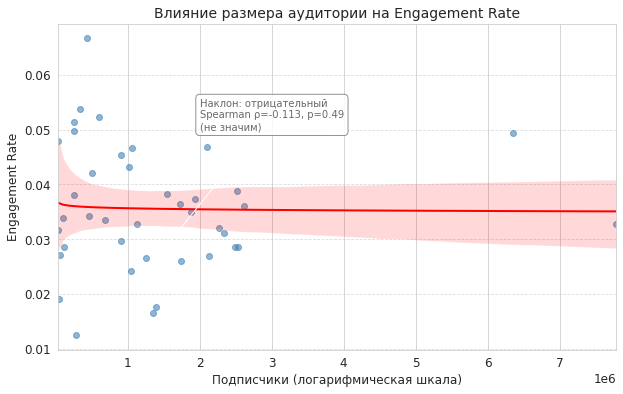

Rho = -0.11266944991052422, p_val= 0.4888135290336747


In [8]:
# ========================================== EDA 2: Влияние аудитории на ER ==========================================

rho, p_val = stats.spearmanr(df_channel_stats['subscribers'], df_channel_stats['engagement'])

plt.figure(figsize=(10, 6))
sns.regplot(
    x='subscribers', y='engagement', data=df_channel_stats,
    logx=True, scatter_kws={'alpha': 0.6, 'color': 'steelblue'},
    line_kws={'color': 'red', 'linewidth': 2})

plt.title('Влияние размера аудитории на Engagement Rate', fontsize=14)
plt.xlabel('Подписчики (логарифмическая шкала)', fontsize=12)
plt.ylabel('Engagement Rate', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

sig = "значим" if p_val < 0.05 else "не значим"
plt.annotate(
    f'Наклон: отрицательный\nSpearman ρ={rho:.3f}, p={p_val:.2f}\n({sig})',
    xy=(1e6, 0.02), xytext=(2e6, 0.05),
    arrowprops=dict(facecolor='gray', arrowstyle='->'),
    fontsize=10, color='dimgray',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.85, edgecolor='gray')
)
plt.show()

print(f'Rho = {rho}, p_val= {p_val}')

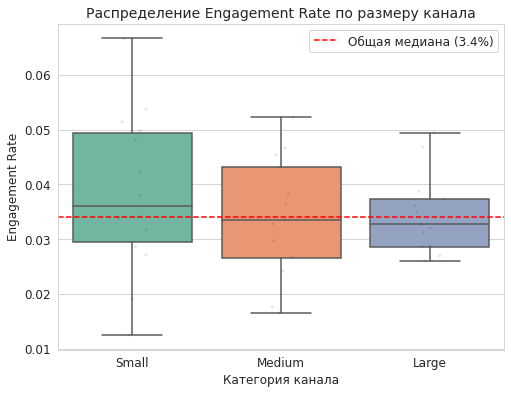

In [9]:
# ========================================== EDA 3: СРАВНЕНИЕ ГРУПП ПО РАЗМЕРУ ================================================

size_order = ['Small', 'Medium', 'Large']
median_er = df_channel_stats['engagement'].median()

plt.figure(figsize=(8, 6))

sns.boxplot(x='channel_size', y='engagement', data=df_channel_stats,
            order=size_order, palette='Set2', showfliers=False)
sns.stripplot(x='channel_size', y='engagement', data=df_channel_stats,
              order=size_order, color='black', alpha=0.1, size=3)

plt.axhline(median_er, color='red', linestyle='--', label=f'Общая медиана ({median_er:.1%})')
plt.title('Распределение Engagement Rate по размеру канала', fontsize=14)
plt.xlabel('Категория канала', fontsize=12)
plt.ylabel('Engagement Rate', fontsize=12)
plt.legend(); plt.show()

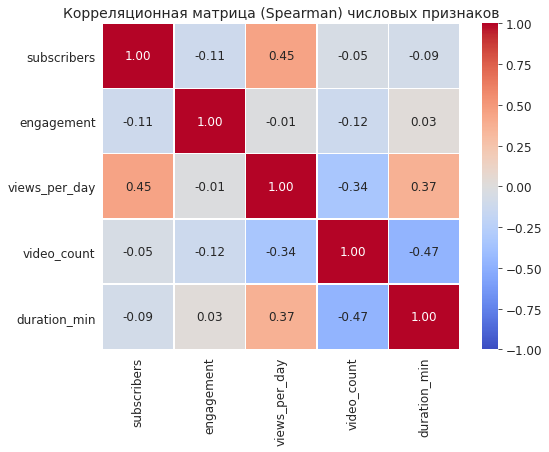

In [10]:
# ============================================== EDA 4: КОРРЕЛЯЦИЯ ПРИЗНАКОВ =================================================

num_cols = ['subscribers', 'engagement', 'views_per_day', 'video_count', 'duration_min']

plt.figure(figsize=(8, 6))
sns.heatmap(df_channel_stats[num_cols].corr(method='spearman'),
            annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Корреляционная матрица (Spearman) числовых признаков', fontsize=14)
plt.show()

## Ключевые выводы по EDA

1. **Тяжёлый хвост.** Подписчики и просмотры асимметричны → агрегируем по медиане, визуализируем в log-шкале.
2. **Размер не предсказывает ER.** ρ≈0, медианы Small/Medium/Large близки → ER несёт независимый сигнал.
3. **Мультиколлинеарность.** `video_count` ↔ `duration_min` — сильная отрицательная связь; в скоринг берём один признак или комбинацию. `subscribers` ↔ `views_per_day` — умеренная, оба признака допустимы.

In [11]:
# ========================================== ЭТАП 4: АНАЛИЗ РАЗМЕРА КАНАЛА (H1) =============================================

print("Проверка гипотезы №1: Влияет ли размер канала на Engagement Rate?\n")

rho, p_spearman = stats.spearmanr(df_channel_stats['subscribers'], df_channel_stats['engagement'])
kw_stat, p_kw = stats.kruskal(*[g['engagement'].values for _, g in df_channel_stats.groupby('channel_size')])

print(f"Spearman: rho={rho:.4f}, p={p_spearman:.3e}")
print(f"Kruskal-Wallis: H={kw_stat:.4f}, p={p_kw:.3e}\n")

summary = df_channel_stats.groupby('channel_size')['engagement'].agg(['count', 'median'])
sizes = summary['count'].to_dict()
medians = summary['median'].apply(lambda x: f'{x:.2%}').to_dict()
print(f"Размеры групп: {sizes}")
print(f"Медианный ER: {medians}")

ALPHA = 0.05
if p_kw < ALPHA or p_spearman < ALPHA:
    print("\nГипотеза №1 подтверждена: обнаружена статистически значимая связь.")
else:
    print(f"\nГипотеза №1 НЕ подтверждена (p_kw={p_kw:.2f}).")
    print(f"При маленькой выборке n={len(df_channel_stats)} мощности теста недостаточно.")

Проверка гипотезы №1: Влияет ли размер канала на Engagement Rate?

Spearman: rho=-0.1127, p=4.888e-01
Kruskal-Wallis: H=1.0424, p=5.938e-01

Размеры групп: {'Small': 14, 'Medium': 13, 'Large': 13}
Медианный ER: {'Small': '3.61%', 'Medium': '3.35%', 'Large': '3.27%'}

Гипотеза №1 НЕ подтверждена (p_kw=0.59).
При маленькой выборке n=40 мощности теста недостаточно.


## Интерпретация гипотезы №1

1. **Статистический вердикт.** Spearman ρ=−0.11, p=0.49; Kruskal-Wallis H=1.04, p=0.59 — статистически значимой связи нет.
2. **Фактические цифры.** Размеры групп: Small=14, Medium=13, Large=13. Медианный ER: Small=3.61%, Medium=3.35%, Large=3.27%.
3. **Для бизнеса.** ER и подписчики — независимые сигналы: размер аудитории не объясняет вовлечённость. Значит, в скоринговой модели оба признака нужно учитывать отдельно — их нельзя заменять друг другом. Конкретные веса обоснованы в разделе «Обоснование весов скоринговой модели».
4. **Ограничение.** Выборка мала, нет контроля на нишу. Корректный вывод: «на этих данных связь не доказана», а не «связи не существует».

In [12]:
print("Проверка гипотезы 2: Влияет ли длительность видео на ER?\n")

model = smf.ols(
    'engagement ~ duration_min + video_age_days + C(channel_id)',
    data=df_longs
).fit(cov_type='cluster', cov_kwds={'groups': df_longs['channel_id']})

coef = model.params.get('duration_min', np.nan)
p_val = model.pvalues.get('duration_min', np.nan)
ci = model.conf_int().loc['duration_min']

print(f"Эффект длительности: {coef:+.6f} (p={p_val:.4f})")
print(f"95% ДИ: [{ci[0]:+.6f}, {ci[1]:+.6f}]")

baseline = df_longs['engagement'].median()
print(f"\nПрактическая интерпретация (медианный ER = {baseline:.2%}):")
print(f"  • +10 мин → ΔER = {coef * 10 * 100:+.4f} п.п.")
print(f"  • +30 мин → ΔER = {coef * 30 * 100:+.4f} п.п.")

alpha = 0.05
if p_val < alpha:
    direction = "положительный" if coef > 0 else "отрицательный"
    print(f"\nГипотеза №2: эффект статистически значим, {direction}.")
    if coef > 0:
        print("Положительное влияние длительности подтверждено.")
    else:
        print("Гипотеза №2 о положительном влиянии не подтверждена: эффект обратный.")
else:
    print("\nГипотеза №2 НЕ подтверждена: эффект длительности статистически не значим (p >= 0.05).")
    print("Точечная оценка может быть отрицательной, но 95% ДИ включает 0; доказательств влияния нет.")

Проверка гипотезы 2: Влияет ли длительность видео на ER?

Эффект длительности: -0.000034 (p=0.1134)
95% ДИ: [-0.000077, +0.000008]

Практическая интерпретация (медианный ER = 3.32%):
  • +10 мин → ΔER = -0.0342 п.п.
  • +30 мин → ΔER = -0.1026 п.п.

Гипотеза №2 НЕ подтверждена: эффект длительности статистически не значим (p >= 0.05).
Точечная оценка может быть отрицательной, но 95% ДИ включает 0; доказательств влияния нет.


## Интерпретация гипотезы №2

Коэффициент при `duration_min` отрицательный, но **статистически не значим** (p≈0.11), 95% ДИ включает 0.

**Точечная оценка:** −0.03 п.п. ER на каждые +10 минут длительности. Практический эффект мал, статистически неотличим от нуля.

**Для бизнеса:** длительность видео не является дискриминирующим признаком при выборе канала. Для оценки удержания нужны retention-метрики YouTube Analytics. Корректный вывод: «на доступных данных длительность не предсказывает ER».

## Обоснование весов скоринговой модели

ER — главный сигнал, подписчики — база охвата с дисконтом, просмотры/день — импульс, стабильность — страховка.

| Признак | Вес | Обоснование |
|---|---|---|
| **ER** | 50% | Прямой индикатор «живой» аудитории. Связь с размером канала не подтверждена (H1), длительность внутри канала не улучшает ER (H2). |
| **Подписчики** | 20% | Обеспечивают базовый охват медиаплана, но не доминируют: большие каналы не дают пропорционального роста вовлеченности. |
| **Просмотры/день** | 15% | Ловят каналы «на подъеме» в рекомендациях и отсекают «мертвых гигантов» с упавшим охватом. |
| **Стабильность (1−CV)** | 15% | Штрафует каналы с непредсказуемым охватом. Для медиабаера предсказуемость KPI важнее пиковых выбросов. |


## Ограничения и следующие шаги

**Ограничения:**
- Данные наблюдательные: выводы описывают связи, но не доказывают причинность.
- Веса модели экспертные, а не калиброванные на бизнес-метриках.
- Нет retention-метрик, CPM/CPE и данных о рекламных интеграциях - нет возможности посчитать ROI
- Выборка — 40 каналов; нет контроля на нишу и сезонность.

**Следующие шаги:**
1. Калибровать веса на исторических CPA/CPE или CPM.
2. Добавить retention и досматриваемость из YouTube Analytics.
3. Проверить устойчивость рейтинга: bootstrap, анализ чувствительности к весам.
4. Расширить выборку и добавить контроль на тематику канала.

In [13]:
# ================================================= ЭТАП 6: СКОРИНГ ===========================================================

# 1. Подготовка данных и расчет метрик (CV)
cv_stats = (df_longs.groupby('channel_id')['views_per_day']. \
            agg(cv_value=lambda x: np.log1p(x).std(ddof=1) / np.log1p(x).mean() if len(x) >= 3 else np.nan,
        cv_robust=lambda x: (np.log1p(x).quantile(0.75) - np.log1p(x).quantile(0.25)) / np.log1p(x).median() if len(x) >= 3 else np.nan
    ).reset_index())

# 2. Сборка финального датафрейма
score_df = (df_channel_stats[['channel_id', 'channel_title', 'subscribers', 'engagement', 'views_per_day', 'video_count']]
    .rename(columns={
        'subscribers': 'subscribers_raw', 
        'engagement': 'engagement_raw', 
        'views_per_day': 'views_per_day_raw'}).merge(cv_stats, on='channel_id', how='left'))

# Заполнение пропусков CV медианой и расчет stability
median_cv = score_df['cv_value'].median()
score_df['cv_value'] = score_df['cv_value'].fillna(median_cv)
score_df['stability_raw'] = (1 - score_df['cv_value']).clip(lower=0)

# 3. Cross-check корреляции
mask = score_df[['cv_value', 'cv_robust']].notna().all(axis=1)
if mask.sum() > 5:
    rho_cv, p_cv = spearmanr(score_df.loc[mask, 'cv_value'], score_df.loc[mask, 'cv_robust'])
    print(f"Spearman (CV vs Robust): rho={rho_cv:.4f}, p={p_cv:.2e}")
    print("→ Ranking устойчив" if rho_cv >= 0.9 else "→ Метрики расходятся")
    print("→ Ranking устойчив" if rho >= 0.9 else "→ Метрики расходятся")

# 4. Трансформация и ранжирование
score_df['subscribers_log'] = np.log1p(score_df['subscribers_raw'])
score_df['views_per_day_log'] = np.log1p(score_df['views_per_day_raw'])

# Ранжируем сразу все колонки одним махом
rank_cols = ['subscribers_log', 'engagement_raw', 'views_per_day_log', 'stability_raw']
score_df[[f'{c}_score' for c in rank_cols]] = score_df[rank_cols].rank(pct=True)

# 5. Итоговый скоринг и сортировка
weights = {'engagement_raw_score': 0.5, 'subscribers_log_score': 0.2, 
           'views_per_day_log_score': 0.15, 'stability_raw_score': 0.15}


score_df['total_score'] = sum(
    (score_df[col] * w for col, w in weights.items()),
    start=score_df[list(weights)[0]] * 0)  # стартовый Series

score_df = score_df.sort_values('total_score', ascending=False).reset_index(drop=True)
score_df['rank'] = range(1, len(score_df) + 1)

# 6. Вывод результатов
print("\n✅ Рейтинг сформирован. Топ-10:")
display(score_df[['rank', 'channel_title', 'total_score', 'engagement_raw_score', 
                  'subscribers_log_score', 'stability_raw_score']].head(10).round(4))

Spearman (CV vs Robust): rho=0.9009, p=2.37e-15
→ Ranking устойчив
→ Метрики расходятся

✅ Рейтинг сформирован. Топ-10:


,rank,channel_title,total_score,engagement_raw_score,subscribers_log_score,stability_raw_score
0,1,Utopia Show,0.8913,0.875,0.975,0.725
1,2,Thoisoi,0.7512,0.825,0.775,0.425
2,3,Филолог всея Руси,0.7475,1.000,0.300,0.625
3,4,Redroom,0.7375,0.800,0.525,0.900
4,5,Научпок,0.7100,0.700,0.900,1.000
5,6,MyGap,0.7050,0.600,0.675,0.975
6,7,АНТРОПОГЕНЕЗ.РУ,0.6738,0.950,0.375,0.500
7,8,Ирина Якутенко,0.6587,0.975,0.275,0.400
8,9,Dameoz,0.6538,0.775,0.450,0.700
9,10,ТОПЛЕС,0.6412,0.425,1.000,0.550


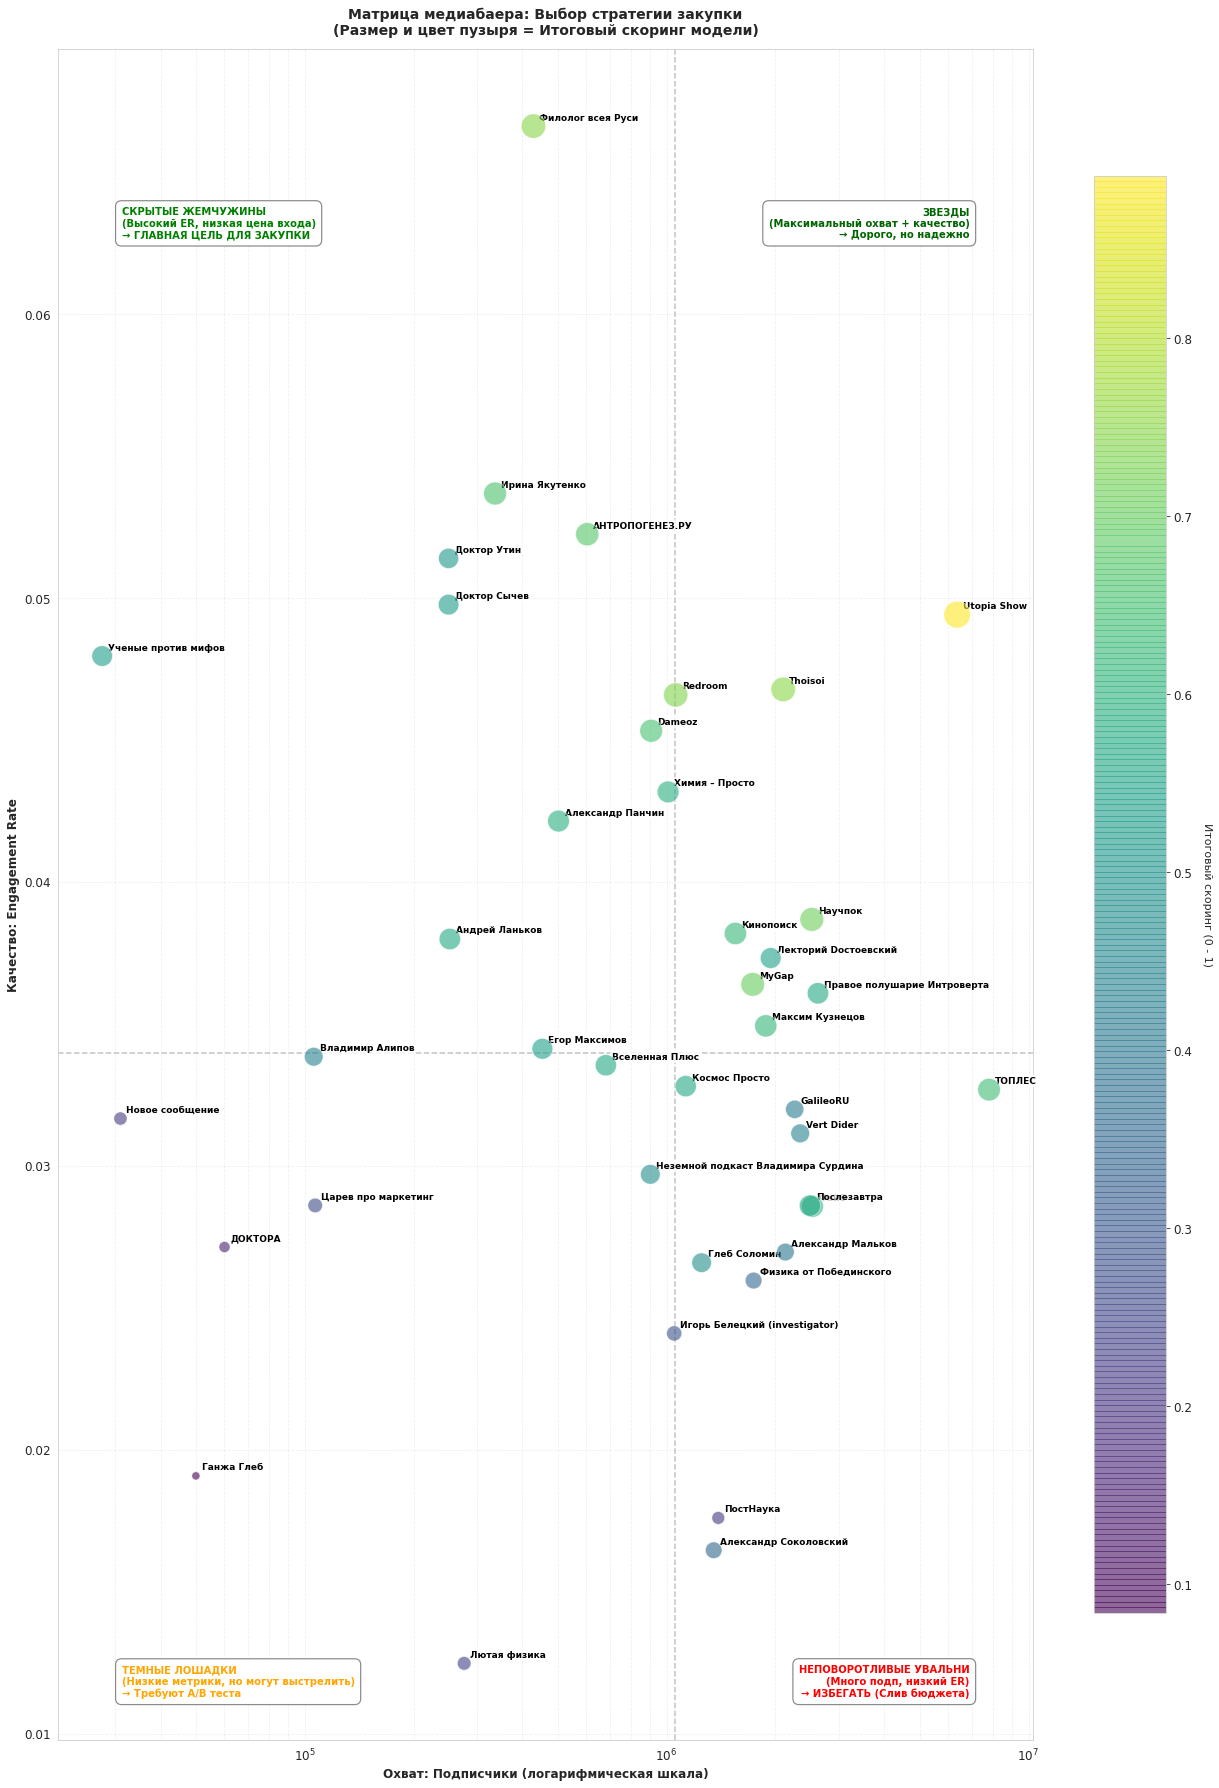

In [14]:
# =================================== ЭТАП 7: ВИЗУАЛИЗАЦИЯ И КВАДРАНТНЫЙ АНАЛИЗ (BCG MATRIX) =================================

# 1. Настройка шрифта для корректного отображения кириллицы
rcParams['font.family'] = 'DejaVu Sans'
rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(18, 25)) # Чуть увеличили размер для лучшей читаемости подписей

# 2. Рисуем точки (Размер и цвет зависят от итогового скоринга)
scatter = ax.scatter(
    score_df['subscribers_raw'], 
    score_df['engagement_raw'], 
    s=score_df['total_score'] * 800,
    c=score_df['total_score'], 
    cmap='viridis', 
    alpha=0.6, # Чуть снизили прозрачность точек, чтобы текст читался лучше
    edgecolors='white', 
    linewidth=0.8,
    zorder=5
)

# 3. Линии разделения (Медианы по выборке)
median_subs = score_df['subscribers_raw'].median()
median_er = score_df['engagement_raw'].median()

ax.axvline(median_subs, color='darkgray', linestyle='--', linewidth=1.5, alpha=0.7, zorder=1)
ax.axhline(median_er, color='darkgray', linestyle='--', linewidth=1.5, alpha=0.7, zorder=1)

# 4. Настройка осей (Логарифм для подписчиков)
ax.set_xscale('log')
ax.set_xlabel('Охват: Подписчики (логарифмическая шкала)', fontsize=12, fontweight='bold')
ax.set_ylabel('Качество: Engagement Rate', fontsize=12, fontweight='bold')
ax.set_title('Матрица медиабаера: Выбор стратегии закупки\n(Размер и цвет пузыря = Итоговый скоринг модели)', 
             fontsize=14, fontweight='bold', pad=15)

# 5. Подписи квадрантов
props = dict(boxstyle='round,pad=0.6', facecolor='white', alpha=0.92, edgecolor='gray', linewidth=1.2)
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()

ax.text(x_min * 1.5, y_max * 0.92, 
        'СКРЫТЫЕ ЖЕМЧУЖИНЫ\n(Высокий ER, низкая цена входа)\n→ ГЛАВНАЯ ЦЕЛЬ ДЛЯ ЗАКУПКИ', 
        fontsize=10, verticalalignment='top', bbox=props, color='green', fontweight='bold', zorder=10)

ax.text(x_max / 1.5, y_max * 0.92, 
        'ЗВЕЗДЫ\n(Максимальный охват + качество)\n→ Дорого, но надежно', 
        fontsize=10, verticalalignment='top', horizontalalignment='right', bbox=props, color='darkgreen', fontweight='bold', zorder=10)

ax.text(x_min * 1.5, y_min * 1.15, 
        'ТЕМНЫЕ ЛОШАДКИ\n(Низкие метрики, но могут выстрелить)\n→ Требуют A/B теста', 
        fontsize=10, verticalalignment='bottom', bbox=props, color='orange', fontweight='bold', zorder=10)

ax.text(x_max / 1.5, y_min * 1.15, 
        'НЕПОВОРОТЛИВЫЕ УВАЛЬНИ\n(Много подп, низкий ER)\n→ ИЗБЕГАТЬ (Слив бюджета)', 
        fontsize=10, verticalalignment='bottom', horizontalalignment='right', bbox=props, color='red', fontweight='bold', zorder=10)

# ============================================== ПОДПИСИ ДЛЯ КАНАЛОВ ==========================================================

for idx, row in score_df.iterrows():
    ax.annotate(
        row['channel_title'],
        xy=(row['subscribers_raw'], row['engagement_raw']), # Координаты точки (автоматически учитывают log scale)
        xytext=(6, 6),                                      # Сдвиг текста вправо и вверх на 6 пикселей
        textcoords='offset points',
        fontsize=9,
        fontweight='bold',
        color='black',
        # Белая полупрозрачная подложка, чтобы текст читался поверх любых элементов
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='none'))

# Легенда (Colorbar)
cbar = plt.colorbar(scatter, ax=ax, shrink=0.85)
cbar.set_label('Итоговый скоринг (0 - 1)', rotation=270, labelpad=20, fontsize=11)

# Сетка для удобства чтения
ax.grid(True, which="both", ls="--", alpha=0.3, zorder=0)
plt.tight_layout()
os.makedirs('reports/figures', exist_ok=True)
plt.savefig('reports/figures/bcg_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
#============================================= ЭТАП 8: ВЫВОД И СОХРАНЕНИЕ ДАННЫХ ==============================================

print("\nВыводы:")
print("1. Гипотеза №1: НЕ подтверждена. В выборке нет статистически значимой связи размера канала и ER.")
print(f"   Spearman rho={rho:.2f}, p={p_spearman:.2f}; Kruskal-Wallis p={p_kw:.2f}.")
print(f"2. Гипотеза №2: НЕ подтверждена. Эффект длительности статистически не значим (p≈{p_val:.2f}), 95% ДИ включает 0.")
print("   Точечная оценка слабо отрицательная, практический эффект мал. Это ассоциация, не причинность.")
print("\nОграничения: n=40 каналов, наблюдательные данные, экспертные веса, нет retention/CPM/CPA, нет контроля на нишу.")

os.makedirs('reports', exist_ok=True)
score_df.to_csv('reports/channel_scoring.csv', index=False, encoding='utf-8-sig')
df_channel_stats.to_csv('reports/channel_stats.csv', index=False, encoding='utf-8-sig')


Выводы:
1. Гипотеза №1: НЕ подтверждена. В выборке нет статистически значимой связи размера канала и ER.
   Spearman rho=-0.11, p=0.49; Kruskal-Wallis p=0.59.
2. Гипотеза №2: НЕ подтверждена. Эффект длительности статистически не значим (p≈0.11), 95% ДИ включает 0.
   Точечная оценка слабо отрицательная, практический эффект мал. Это ассоциация, не причинность.

Ограничения: n=40 каналов, наблюдательные данные, экспертные веса, нет retention/CPM/CPA, нет контроля на нишу.


# Итоговый вывод

Скоринг выявляет каналы с лучшим соотношением «вовлеченность / охват». Ключевой вывод: **размер канала не предсказывает ER**, поэтому закупка только по подписчикам ведет к переплате.

**Как использовать рейтинг (матрица медиабаера):**
- **55% бюджета** — «Скрытые жемчужины» (высокий ER, низкий охват): *Филолог всея Руси, Ирина Якутенко, Ученые против мифов*
- **35% бюджета** — «Звезды» (максимальный охват, стабильный ER): *Utopia Show, Thoisoi, Redroom*
- **10% бюджета** — «Тёмные лошадки» (растущие каналы): *Новое сообщение, ДОКТОРА*
- **0% бюджета** - «Мёртвые гиганты»: стоит избежать покупки рекламы

Пример интерпретации, не расчёт.

**Ограничения:** веса экспертные, данные наблюдательные, нет retention-метрик и CPM. При возможности нужна калибровка весов на исторических CPA/CPE.